## **Multi-Channel Marketing Attribution (Data Analysis Project)**

## Business Problem

NovaCart increased marketing spend by 40% year-over-year across four channels (Google Ads, Meta, Affiliate, Email), but overall revenue growth only kept pace at 12% YoY. Finance has flagged this gap ahead of the Q4 board meeting. This analysis identifies which channels are acquiring customers who generate long-term value versus which are generating low-value, one-time transactions that don't justify their acquisition cost — and recommends how marketing budget should be reallocated.

## Objectives

1. Calculate **Customer Acquisition Cost (CAC)** by channel, month-over-month, across the 18-month period.
2. Calculate **Customer Lifetime Value (LTV)** by channel, using a defined time horizon.
3. Compute the **LTV:CAC ratio** per channel and flag channels performing below a 3:1 target (or below 1:1, where the channel is losing money outright).
4. Assess whether current **budget allocation** matches where profitable, retained customers actually come from.
5. Recommend where a **20% budget cut** should land next quarter, with the least damage to long-term revenue — including the tradeoff involved in that recommendation.

## **Loading the Library**

In [1]:
import os 
import numpy as np 
import pandas as pd 
import mysql.connector as sql

from warnings import filterwarnings
filterwarnings('ignore') # To ignore all sorts of Warnings that shows up in the code 

In [2]:
conn = sql.connect(
    host = "localhost",
    user = "root",
    password = os.environ.get("HR_DB_PASSWORD"),
    database = "novacart_staging"
)
print("Connected..")

Connected..


## **Loading the Data**

In [3]:
customer = pd.read_sql("select * from customers_raw;",conn)
marketing = pd.read_sql("select * from marketing_spend_raw;",conn)
order = pd.read_sql("select * from orders_raw;",conn)

In [4]:
customer.head()

,customer_id,customer_name,email,signup_date_raw,acquisition_channel,city
0,CUST113782,Pari Sharma,pari.sharma338@gmail.com,08/08/2025,Affiliate,Hyderabad
1,CUST110010,Navya Mehta,navya.mehta456@gmail.com,2025-06-05,Affiliate,Delhi
2,CUST113812,Neha Agarwal,neha.agarwal200@gmail.com,2025-12-26,Affiliates,Kolkata
3,CUST104224,Sneha Gupta,sneha.gupta261@gmail.com,02-04-2026,Google Ads,Lucknow
4,CUST115698,Neha Mukherjee,neha.mukherjee26@gmail.com,23/02/2026,Meta,Pune


In [5]:
marketing.head()

,month_raw,channel,spend_amount_raw
0,2026-04,Google Ads,1104783.24
1,2025-08,Google Ads,"₹1,080,083"
2,2026-04,Meta,1469447.21
3,2026-06,Email,76140.57
4,2025-10,affiliate,418931.82


In [6]:
order.head()

,order_id,customer_id,order_date_raw,order_amount_raw
0,ORD0009524,CUST115426,2025-07-17,
1,ORD0011529,CUST113245,06/19/2026,1731.4
2,ORD0001767,CUST106337,2025-07-09,1622.7
3,ORD0018454,CUST100702,11/06/2025,1863.35
4,ORD0029855,CUST102730,2025-03-15,1409.93


## **Data Cleaning**

In [7]:
customer.shape # Rows and Columns 

(20300, 6)

In [8]:
customer.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20300 entries, 0 to 20299
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   customer_id          20300 non-null  object
 1   customer_name        20300 non-null  object
 2   email                20300 non-null  object
 3   signup_date_raw      20300 non-null  object
 4   acquisition_channel  20300 non-null  object
 5   city                 20300 non-null  object
dtypes: object(6)
memory usage: 951.7+ KB


In [9]:
# Identifying the unique values 
customer.nunique()

customer_id            20000
customer_name            600
email                  18636
signup_date_raw         2404
acquisition_channel       21
city                      10
dtype: int64

In [10]:
customer.isnull().sum()

customer_id            0
customer_name          0
email                  0
signup_date_raw        0
acquisition_channel    0
city                   0
dtype: int64

## **Removing Duplicate Rows**

In [11]:
print(f"Deleted {customer.duplicated().sum()} duplicate rows.")
customer = customer.drop_duplicates()

Deleted 287 duplicate rows.


In [12]:
# Deleting Duplicate Customer ID's 
print(f"Deleted {customer.duplicated(subset= "customer_id").sum()} Duplicate Customer ID's")
customer = customer.drop_duplicates(subset= "customer_id",keep="first") 

Deleted 13 Duplicate Customer ID's


In [13]:
customer["signup_date_raw"] = pd.to_datetime(
    customer["signup_date_raw"], format="mixed", dayfirst=True
)

customer["signup_date_raw"] = customer["signup_date_raw"].dt.strftime("%Y-%m-%d")

In [14]:
customer["acquisition_channel"].unique()

array(['Affiliate', 'Affiliates', 'Google Ads', 'Meta',
       'facebook/instagram', 'google', 'Instagram', 'Email', 'affiliate',
       'affiliate ', 'google ads', 'email', 'Facebook', 'GOOGLE ADS',
       'Google', 'meta', 'AFFILIATE', 'Email Marketing', 'FB', 'E-mail',
       'EMAIL'], dtype=object)

In [15]:
channel_map = {
    # Affiliate
    'Affiliate': 'Affiliate',
    'Affiliates': 'Affiliate',
    'affiliate': 'Affiliate',
    'affiliate ': 'Affiliate',
    'AFFILIATE': 'Affiliate',

    # Google
    'Google Ads': 'Google',
    'google ads': 'Google',
    'GOOGLE ADS': 'Google',
    'google': 'Google',
    'Google': 'Google',

    # Meta
    'Meta': 'Meta',
    'meta': 'Meta',
    'facebook/instagram': 'Meta',
    'Facebook': 'Meta',
    'FB': 'Meta',
    'Instagram': 'Meta',

    # Email
    'Email': 'Email Marketing',
    'email': 'Email Marketing',
    'EMAIL': 'Email Marketing',
    'Email Marketing': 'Email Marketing',
    'E-mail': 'Email Marketing'
}

customer["acquisition_channel"] = customer["acquisition_channel"].map(channel_map)

In [16]:
customer.nunique()

customer_id            20000
customer_name            600
email                  18631
signup_date_raw          579
acquisition_channel        4
city                      10
dtype: int64

## **Modifying the Datatypes** 

In [17]:
customer["signup_date_raw"] = pd.to_datetime(customer["signup_date_raw"])
customer.info()

<class 'pandas.core.frame.DataFrame'>
Index: 20000 entries, 0 to 20299
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   customer_id          20000 non-null  object        
 1   customer_name        20000 non-null  object        
 2   email                20000 non-null  object        
 3   signup_date_raw      20000 non-null  datetime64[ns]
 4   acquisition_channel  20000 non-null  object        
 5   city                 20000 non-null  object        
dtypes: datetime64[ns](1), object(5)
memory usage: 1.1+ MB


## **Modifying the column names** 

In [18]:
cols = {
    "customer_name" : "Customer_name",
    "customer_id" : "Customer_id",
    "email" : "Email",
    "signup_date_raw" : "Signup_date",
    "acquisition_channel" : "Acquisition_channel",
    "city" : "City"
}

customer.rename(columns = cols,inplace = True)
print("Columns Name Modified ..")

Columns Name Modified ..


In [19]:
# Checking the Cleaned DataFrame 'customer'
customer.head(25)

,Customer_id,Customer_name,Email,Signup_date,Acquisition_channel,City
0,CUST113782,Pari Sharma,pari.sharma338@gmail.com,2025-08-08,Affiliate,Hyderabad
1,CUST110010,Navya Mehta,navya.mehta456@gmail.com,2025-06-05,Affiliate,Delhi
2,CUST113812,Neha Agarwal,neha.agarwal200@gmail.com,2025-12-26,Affiliate,Kolkata
3,CUST104224,Sneha Gupta,sneha.gupta261@gmail.com,2026-04-02,Google,Lucknow
4,CUST115698,Neha Mukherjee,neha.mukherjee26@gmail.com,2026-02-23,Meta,Pune
5,CUST107619,Kavya Mukherjee,kavya.mukherjee488@gmail.com,2025-06-14,Affiliate,Bangalore
6,CUST106792,Diya Bose,diya.bose273@gmail.com,2025-06-13,Affiliate,Delhi
7,CUST116668,Arjun Bose,arjun.bose332@yahoo.com,2025-03-31,Meta,Kolkata
8,CUST102017,Meera Banerjee,,2026-03-09,Google,Lucknow
9,CUST113348,Kavya Joshi,kavya.joshi333@gmail.com,2025-06-23,Meta,Bangalore


In [20]:
marketing.shape # Rows and columns 

(73, 3)

In [21]:
marketing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 73 entries, 0 to 72
Data columns (total 3 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   month_raw         73 non-null     object
 1   channel           73 non-null     object
 2   spend_amount_raw  73 non-null     object
dtypes: object(3)
memory usage: 1.8+ KB


In [22]:
marketing.isnull().sum()

month_raw           0
channel             0
spend_amount_raw    0
dtype: int64

## **Removing the Duplicate Values**

In [23]:
marketing = marketing.drop_duplicates()

In [24]:
marketing.nunique()

month_raw           32
channel             18
spend_amount_raw    70
dtype: int64

In [25]:
from dateutil.parser import parse

# 1. Parse every format (including 'Jul-25') to a valid datetime
marketing["month_raw"] = pd.to_datetime(
    marketing["month_raw"].astype(str).apply(parse)
)

# 2. Format to YYYY-MM
marketing["month_raw"] = marketing["month_raw"].dt.strftime("%Y-%m")

In [26]:
marketing["channel"] = marketing["channel"].map(channel_map)

In [27]:
# 1. Convert to string, remove '₹', commas, and any non-numeric whitespace
marketing["spend_amount_raw"] = (
    marketing["spend_amount_raw"]
    .astype(str)
    .str.replace("₹", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)

# 2. Convert to float (numeric)
marketing["spend_amount_raw"] = pd.to_numeric(
    marketing["spend_amount_raw"]
)

marketing["spend_amount_raw"] = np.round(marketing["spend_amount_raw"])

## **Modifying the DataTypes**

In [28]:
marketing["spend_amount_raw"] = marketing["spend_amount_raw"].astype(int)
marketing["month_raw"] = pd.to_datetime(marketing["month_raw"])

marketing.info()

<class 'pandas.core.frame.DataFrame'>
Index: 70 entries, 0 to 72
Data columns (total 3 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   month_raw         70 non-null     datetime64[ns]
 1   channel           70 non-null     object        
 2   spend_amount_raw  70 non-null     int64         
dtypes: datetime64[ns](1), int64(1), object(1)
memory usage: 2.2+ KB


## **Modifying the column names** 

In [29]:
cols = {
    "month_raw" : "Month",
    "channel" : "Channel",
    "spend_amount_raw" : "Spend_amount"
}

marketing.rename(columns = cols,inplace = True)
print("Columns Name Modified ..")

Columns Name Modified ..


In [30]:
marketing.head(15)

,Month,Channel,Spend_amount
0,2026-04-01,Google,1104783
1,2025-08-01,Google,1080083
2,2026-04-01,Meta,1469447
3,2026-06-01,Email Marketing,76141
4,2025-10-01,Affiliate,418932
5,2025-05-01,Email Marketing,65377
6,2025-03-01,Email Marketing,61971
7,2026-08-01,Email Marketing,60381
8,2025-08-01,Meta,974131
9,2025-01-01,Affiliate,356311


In [31]:
order.shape

(36417, 4)

In [32]:
order.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36417 entries, 0 to 36416
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   order_id          36417 non-null  object
 1   customer_id       36417 non-null  object
 2   order_date_raw    36417 non-null  object
 3   order_amount_raw  36417 non-null  object
dtypes: object(4)
memory usage: 1.1+ MB


In [33]:
order.isnull().sum()

order_id            0
customer_id         0
order_date_raw      0
order_amount_raw    0
dtype: int64

## **Removing the Duplicates**

In [34]:
print(f"Deleted {order.duplicated().sum()} Duplicate Rows")
order = order.drop_duplicates()

Deleted 361 Duplicate Rows


In [35]:
print(f"Deleted {order.duplicated(subset="order_id").sum()} Duplicate Order ID's")
order = order.drop_duplicates(subset="order_id",keep = "first")


Deleted 0 Duplicate Order ID's


In [36]:
order.nunique()

order_id            36056
customer_id         20286
order_date_raw       2653
order_amount_raw    32216
dtype: int64

In [37]:
order["order_date_raw"] = pd.to_datetime(
    order["order_date_raw"], format="mixed", dayfirst=True
)

order["order_date_raw"] = order["order_date_raw"].dt.strftime("%Y-%m-%d")

In [38]:
order["order_amount_raw"] = (
    order["order_amount_raw"]
    .astype(str)
    .str.replace("₹","",regex = False)
    .str.replace("-","",regex = False)
    .str.replace(",","",regex = False)
    .str.strip()
)

In [39]:
order["order_amount_raw"] = pd.to_numeric(order["order_amount_raw"])
order["order_amount_raw"] = np.round(order["order_amount_raw"])

In [40]:
order[order["order_amount_raw"].isnull()].head()

,order_id,customer_id,order_date_raw,order_amount_raw
0,ORD0009524,CUST115426,2025-07-17,NaN
29,ORD0005974,CUST108564,2025-10-11,NaN
34,ORD0032721,CUST109053,2025-12-16,NaN
89,ORD0030667,CUST108232,2025-09-17,NaN
145,ORD0013647,CUST107626,2026-03-23,NaN


In [41]:
order.describe(include = 'number').T

,count,mean,std,min,25%,50%,75%,max
order_amount_raw,34974.0,2654.221164,16301.521165,50.0,922.0,1218.0,1541.0,506254.0


In [42]:
median_value = order["order_amount_raw"].median()
### issue 
# Calculate the "median" and fill the missing value 
order["order_amount_raw"] = order["order_amount_raw"].fillna(np.round(median_value))

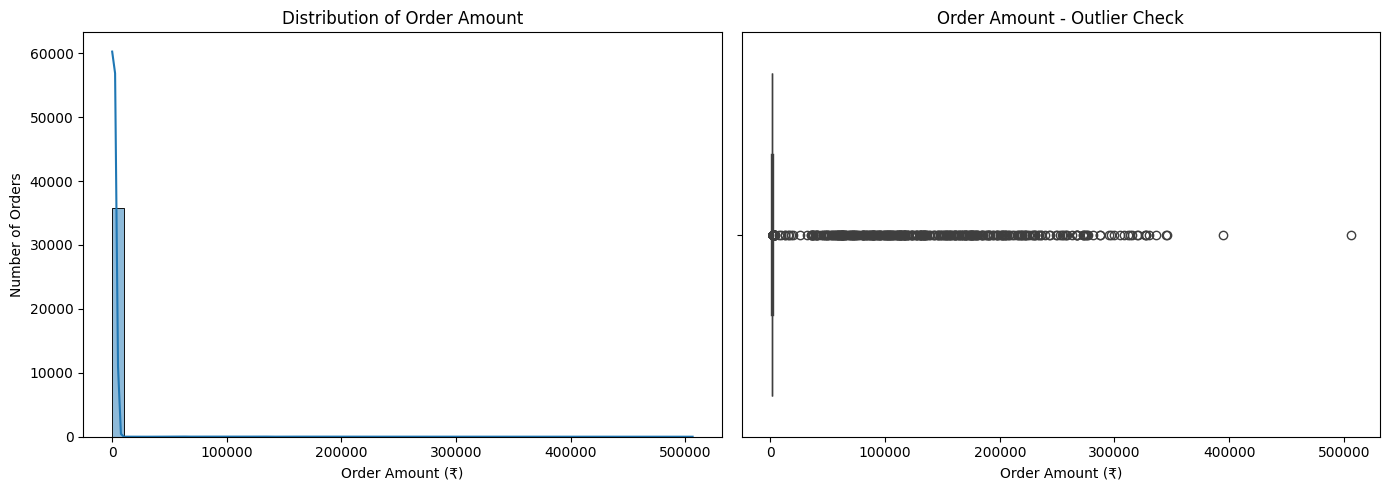

count     36056.000000
mean       2611.121783
std       16056.925896
min          50.000000
25%         932.000000
50%        1218.000000
75%        1529.000000
max      506254.000000
Name: order_amount_raw, dtype: float64

Skewness: 13.944129752099483


In [44]:
import matplotlib.pyplot as plt 
import seaborn as sns 

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram - shows overall shape/skew
sns.histplot(data=order, x="order_amount_raw", bins=50, ax=axes[0], kde=True)
axes[0].set_title("Distribution of Order Amount")
axes[0].set_xlabel("Order Amount (₹)")
axes[0].set_ylabel("Number of Orders")

# Boxplot - makes outliers explicit
sns.boxplot(data=order, x="order_amount_raw", ax=axes[1])
axes[1].set_title("Order Amount - Outlier Check")
axes[1].set_xlabel("Order Amount (₹)")

plt.tight_layout()
plt.show()

print(order["order_amount_raw"].describe())
print("\nSkewness:", order["order_amount_raw"].skew())

### Findings — Order Amount Distribution

- **Data quality note:** ~1,082 rows had a missing `order_amount`. Since the distribution is heavily right-skewed, these were filled with the **median (₹1,218)** rather than the mean, which would have been pulled upward by extreme values.

- The distribution of `Order_amount` is **heavily right-skewed** (skewness = **13.94**), meaning a small number of extremely large orders are pulling the distribution far outside its normal range.

- **Mean (₹2,611) is more than double the median (₹1,218)** — this gap indicates the average order value is being artificially inflated by a handful of unusually large orders, not by a genuinely higher typical spend.

- **75% of all orders fall below ₹1,529**, yet the maximum order value is **₹506,254** — over 330x the 75th percentile. This gap strongly suggests these extreme values are data entry errors rather than legitimate large purchases.

- The boxplot confirms this: the vast majority of orders cluster in a narrow band near ₹0–1,500, while a long tail of outlier points (flagged individually as circles) extends out to ₹300,000–₹500,000.

- **Implication:** if left unaddressed, these outliers would inflate revenue and LTV calculations for any channel they happen to fall under, leading to an inaccurate picture of channel performance. These rows are treated as untrustworthy data and removed using the IQR method before proceeding to the CAC/LTV analysis.

- **After outlier removal** (549 rows, 1.52% of the dataset): skewness drops to **0.12**, mean (₹1,224) and median (₹1,218) converge, and the distribution becomes approximately symmetric — confirming the cleanup worked as intended.

In [45]:
# ------------------------------------------------------------
# Remove outlier orders using the IQR method.
# Order_amount has extreme values (e.g. ₹500,000+) that are far
# beyond what a normal order looks like (75% of orders are under
# ₹1,528). These distort the mean/LTV calculations used later,
# so they are removed here as untrustworthy data.
# ------------------------------------------------------------

# check what's being flagged before removing anything
print(order.sort_values("order_amount_raw", ascending=False).head(20))

Q1 = order["order_amount_raw"].quantile(0.25)
Q3 = order["order_amount_raw"].quantile(0.75)
IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR
lower_bound = Q1 - 1.5 * IQR

before = len(order)

order = order[
    (order["order_amount_raw"] >= lower_bound) &
    (order["order_amount_raw"] <= upper_bound)
].reset_index(drop=True)

after = len(order)
print(f"Dropped {before - after} outlier rows ({(before - after) / before * 100:.2f}%)")

# confirm the fix worked - mean and median should now be much closer
print(order["order_amount_raw"].describe())
print("Skewness:", order["order_amount_raw"].skew())

         order_id customer_id order_date_raw  order_amount_raw
34554  ORD0011089  CUST118356     2025-12-29          506254.0
15619  ORD0033603  CUST112785     2025-07-27          394920.0
4809   ORD0032513  CUST108889     2025-08-13          345432.0
32791  ORD0020913  CUST115508     2025-04-10          344572.0
3778   ORD0002470  CUST115722     2025-11-23          336022.0
660    ORD0014471  CUST101234     2025-04-01          330148.0
19195  ORD0035838  CUST900067     2025-02-13          327435.0
34411  ORD0033475  CUST114330     2025-02-13          327435.0
12023  ORD0022577  CUST116511     2025-09-03          327037.0
12994  ORD0005012  CUST117197     2026-04-04          320814.0
29045  ORD0003254  CUST116710     2025-03-23          320001.0
10427  ORD0005836  CUST104426     2026-05-01          315015.0
24105  ORD0031428  CUST109365     2026-03-08          313170.0
10380  ORD0023277  CUST116369     2025-06-07          312092.0
13517  ORD0024053  CUST104619     2025-03-28          3

## **Modifying the Datatypes** 

In [46]:
order["order_date_raw"] = pd.to_datetime(order["order_date_raw"])
order["order_amount_raw"] = order["order_amount_raw"].astype(int)

order.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35507 entries, 0 to 35506
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   order_id          35507 non-null  object        
 1   customer_id       35507 non-null  object        
 2   order_date_raw    35507 non-null  datetime64[ns]
 3   order_amount_raw  35507 non-null  int64         
dtypes: datetime64[ns](1), int64(1), object(2)
memory usage: 1.1+ MB


## **Modifying the column names**

In [47]:
cols = {
    "order_id" : "Order_id",
    "customer_id" : "Customer_id",
    "order_date_raw" : "Order_date",
    "order_amount_raw" : "Order_amount"
}

order.rename(columns = cols,inplace = True)
print("Columns Name Modified ..")

Columns Name Modified ..


In [48]:
order.head(25)

,Order_id,Customer_id,Order_date,Order_amount
0,ORD0009524,CUST115426,2025-07-17,1218
1,ORD0011529,CUST113245,2026-06-19,1731
2,ORD0001767,CUST106337,2025-07-09,1623
3,ORD0018454,CUST100702,2025-06-11,1863
4,ORD0029855,CUST102730,2025-03-15,1410
5,ORD0032417,CUST100999,2025-06-09,1718
6,ORD0025817,CUST103239,2026-02-03,1843
7,ORD0003952,CUST102941,2025-05-09,1836
8,ORD0034036,CUST115579,2026-02-21,306
9,ORD0022891,CUST116289,2025-11-25,1254


In [49]:
customer.to_csv("customer.csv",index = False)
marketing.to_csv("marketing.csv",index = False)
order.to_csv("order.csv",index = False)

print("Success..")

Success..
